In [1]:
import kagglehub
import pandas

path = kagglehub.dataset_download("gauravdhamane/gwa-bitbrains")

print("Path to dataset files:", path)

100%|██████████| 129M/129M [00:00<00:00, 187MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/gauravdhamane/gwa-bitbrains/versions/1


Loaded VM file: /root/.cache/kagglehub/datasets/gauravdhamane/gwa-bitbrains/versions/1/fastStorage/2013-8/657.csv (8612 records)


,Timestamp,CPU usage [%],Memory usage [KB],Disk read throughput [KB/s],Disk write throughput [KB/s],Network received throughput [KB/s],Network transmitted throughput [KB/s]
0,1970-01-16 22:18:34.846,2.000000,425022.133333,0.0,20.133333,2.066667,4.066667
1,1970-01-16 22:18:35.146,2.433333,380282.400000,0.0,27.266667,1.933333,4.200000
2,1970-01-16 22:18:35.446,2.500000,452983.466667,0.0,20.200000,2.133333,4.200000
3,1970-01-16 22:18:35.746,5.000000,251656.000000,0.0,20.200000,2.133333,4.200000
4,1970-01-16 22:18:36.046,2.566667,391466.666667,0.0,20.200000,2.066667,4.000000


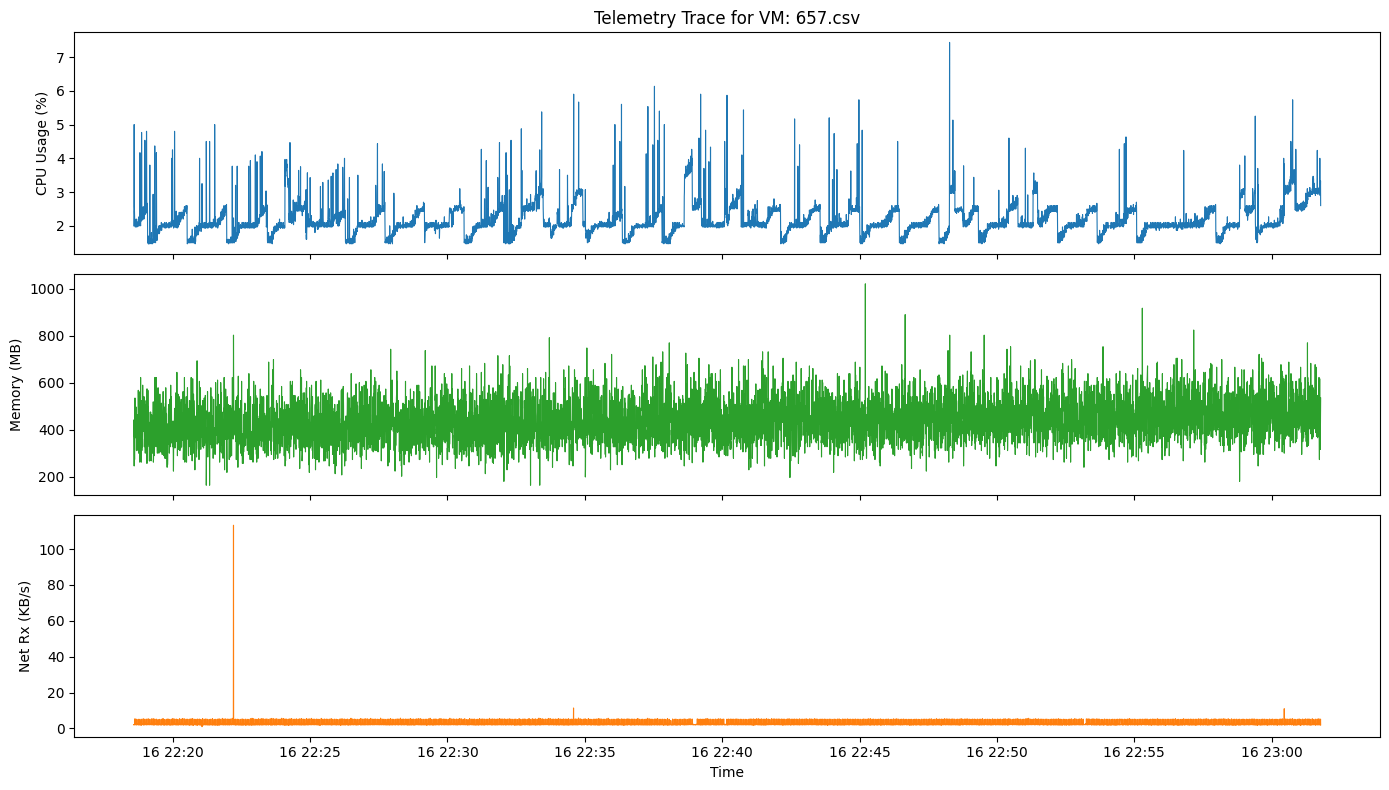

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_path = "/root/.cache/kagglehub/datasets/gauravdhamane/gwa-bitbrains/versions/1/fastStorage/2013-8/657.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Could not find file at: {csv_path}. Check the path in the left sidebar file explorer.")

# Load CSV (handles both Bitbrains ';\t' separator and standard ',' separator)
with open(csv_path, "r") as f:
    first_line = f.readline()
sep = r";\t" if ";\t" in first_line else (";" if ";" in first_line else ",")

df = pd.read_csv(csv_path, sep=sep, engine="python")
df.columns = df.columns.str.strip()

print(f"Loaded VM file: {csv_path} ({len(df)} records)")

# Convert Unix timestamp (ms) to readable datetime
df["Timestamp"] = pd.to_datetime(df["Timestamp [ms]"], unit="ms")
df = df.sort_values("Timestamp").reset_index(drop=True)

# Select relevant cloud infrastructure features
features = [
    "CPU usage [%]",
    "Memory usage [KB]",
    "Disk read throughput [KB/s]",
    "Disk write throughput [KB/s]",
    "Network received throughput [KB/s]",
    "Network transmitted throughput [KB/s]",
]

df = df[["Timestamp"] + features].dropna()
display(df.head())

# Plot raw telemetry overview
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
axes[0].plot(df["Timestamp"], df["CPU usage [%]"], color="#1f77b4", lw=0.8)
axes[0].set_ylabel("CPU Usage (%)")
axes[0].set_title(f"Telemetry Trace for VM: {os.path.basename(csv_path)}")

axes[1].plot(df["Timestamp"], df["Memory usage [KB]"] / 1024, color="#2ca02c", lw=0.8)
axes[1].set_ylabel("Memory (MB)")

axes[2].plot(df["Timestamp"], df["Network received throughput [KB/s]"], color="#ff7f0e", lw=0.8)
axes[2].set_ylabel("Net Rx (KB/s)")
axes[2].set_xlabel("Time")
plt.tight_layout()
plt.show()

In [3]:
df


,Timestamp,CPU usage [%],Memory usage [KB],Disk read throughput [KB/s],Disk write throughput [KB/s],Network received throughput [KB/s],Network transmitted throughput [KB/s]
0,1970-01-16 22:18:34.846,2.000000,425022.133333,0.0,20.133333,2.066667,4.066667
1,1970-01-16 22:18:35.146,2.433333,380282.400000,0.0,27.266667,1.933333,4.200000
2,1970-01-16 22:18:35.446,2.500000,452983.466667,0.0,20.200000,2.133333,4.200000
3,1970-01-16 22:18:35.746,5.000000,251656.000000,0.0,20.200000,2.133333,4.200000
4,1970-01-16 22:18:36.046,2.566667,391466.666667,0.0,20.200000,2.066667,4.000000
...,...,...,...,...,...,...,...
8607,1970-01-16 23:01:45.598,2.900000,452983.200000,0.0,27.200000,2.066667,4.200000
8608,1970-01-16 23:01:45.898,3.066667,324358.666667,0.0,20.266667,2.466667,4.000000
8609,1970-01-16 23:01:46.198,3.066667,425021.333333,0.0,27.333333,2.000000,4.266667
8610,1970-01-16 23:01:46.498,3.333333,536868.800000,0.0,24.666667,5.200000,4.666667


In [4]:
from sklearn.preprocessing import MinMaxScaler

# 1. Chronological 80/20 Split (NEVER shuffle time series)
train_size = int(len(df) * 0.80)
train_df = df[features].iloc[:train_size]
test_df = df[features].iloc[train_size:]

# 2. Fit scaler ONLY on training data
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_df)
test_scaled = scaler.transform(test_df)

# 3. Create sliding windows (past 12 steps = 1 hour -> predict next 5-min CPU)
LOOKBACK = 12  # 12 * 5 mins = 60 mins of history
TARGET_COL = 0  # Index 0 is 'CPU usage [%]'

def create_sequences(data, lookback, target_col):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i - lookback : i, :])  # All 6 features over lookback window
        y.append(data[i, target_col])          # Next step's CPU usage
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, LOOKBACK, TARGET_COL)
X_test, y_test = create_sequences(test_scaled, LOOKBACK, TARGET_COL)

print(f"X_train shape: {X_train.shape} -> (samples, timesteps, features)")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (6877, 12, 6) -> (samples, timesteps, features)
X_test shape:  (1711, 12, 6)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 12, 64)         │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,137 (121.63 KB)

 Trainable params: 31,137 (121.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.0041 - mae: 0.0354 - val_loss: 0.0024 - val_mae: 0.0235
Epoch 2/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0037 - mae: 0.0311 - val_loss: 0.0024 - val_mae: 0.0260
Epoch 3/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0035 - mae: 0.0294 - val_loss: 0.0023 - val_mae: 0.0249
Epoch 4/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0034 - mae: 0.0289 - val_loss: 0.0022 - val_mae: 0.0228
Epoch 5/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0034 - mae: 0.0283 - val_loss: 0.0021 - val_mae: 0.0229
Epoch 6/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0033 - mae: 0.0280 - val_loss: 0.0020 - val_mae: 0.0221
Epoch 7/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0033 - mae: 0.0275 - val_loss: 0.0020 - val_mae: 0.0206
Epoch 8/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0032 - mae: 0.0272 - val_loss: 0.0020 - val_mae: 0.0234
Epoch 9/35
183/183 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/

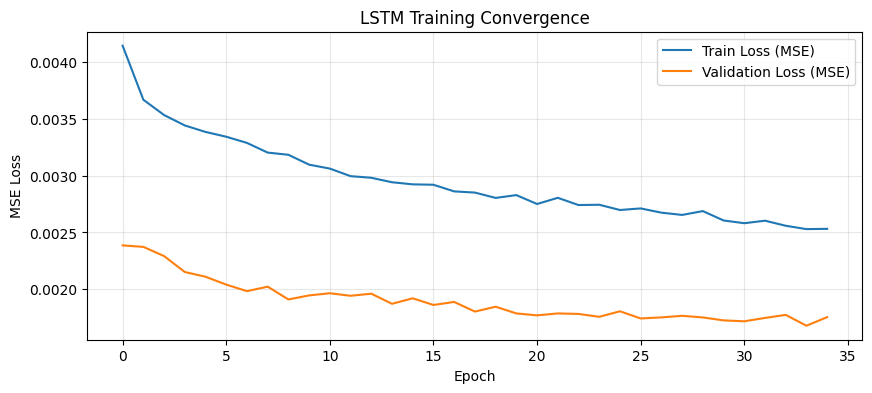

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
model.summary()

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=35,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Plot Training vs Validation Loss
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Train Loss (MSE)")
plt.plot(history.history["val_loss"], label="Validation Loss (MSE)")
plt.title("LSTM Training Convergence")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
--- Model Performance on Unseen Test Data ---
LSTM MAE:           0.089% CPU
LSTM RMSE:          0.207% CPU
Naive Baseline MAE: 0.103% CPU


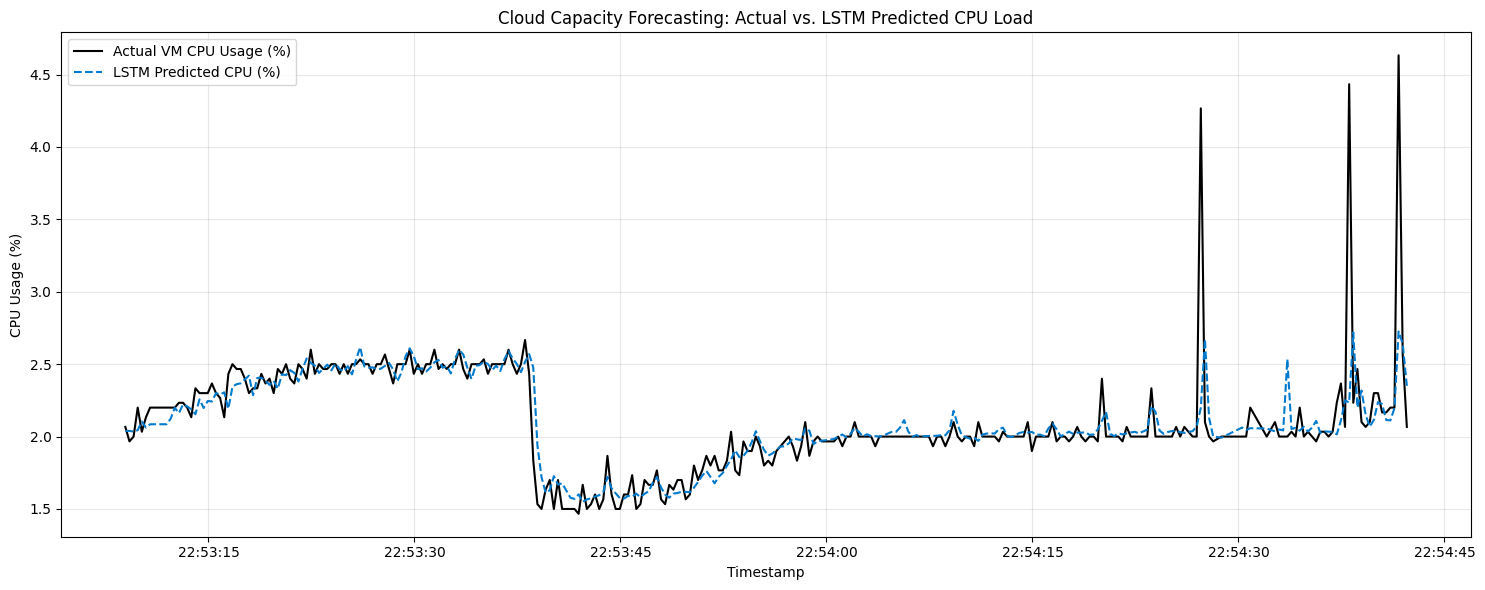

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict on test set
y_pred_scaled = model.predict(X_test)

# Helper to inverse-transform only the target column (CPU %)
def inverse_cpu(scaled_col):
    dummy = np.zeros((len(scaled_col), len(features)))
    dummy[:, TARGET_COL] = scaled_col.flatten()
    return scaler.inverse_transform(dummy)[:, TARGET_COL]

y_true_cpu = inverse_cpu(y_test)
y_pred_cpu = inverse_cpu(y_pred_scaled)

# Naive Baseline: "Next CPU = Current CPU" (t-1 persistence)
naive_pred_cpu = y_true_cpu[:-1]
y_true_aligned = y_true_cpu[1:]
y_pred_aligned = y_pred_cpu[1:]

lstm_mae = mean_absolute_error(y_true_aligned, y_pred_aligned)
lstm_rmse = np.sqrt(mean_squared_error(y_true_aligned, y_pred_aligned))
naive_mae = mean_absolute_error(y_true_aligned, naive_pred_cpu)

print("--- Model Performance on Unseen Test Data ---")
print(f"LSTM MAE:           {lstm_mae:.3f}% CPU")
print(f"LSTM RMSE:          {lstm_rmse:.3f}% CPU")
print(f"Naive Baseline MAE: {naive_mae:.3f}% CPU")

# Showcase Plot: Zoom into a 300-step (~25 hour) window on the test set
window = slice(0, 300)
test_timestamps = df["Timestamp"].iloc[train_size + LOOKBACK + 1 :].values[window]

plt.figure(figsize=(15, 6))
plt.plot(test_timestamps, y_true_aligned[window], label="Actual VM CPU Usage (%)", color="black", lw=1.5)
plt.plot(test_timestamps, y_pred_aligned[window], label="LSTM Predicted CPU (%)", color="#007acc", linestyle="--", lw=1.5)

# Highlight proactive auto-scaling threshold (e.g., 70% CPU)
#SCALE_THRESHOLD = 70.0
#plt.axhline(SCALE_THRESHOLD, color="red", linestyle=":", label=f"Auto-Scale Trigger ({SCALE_THRESHOLD}%)")
#plt.fill_between(
#    test_timestamps, y_pred_aligned[window], SCALE_THRESHOLD,
#    where=(y_pred_aligned[window] >= SCALE_THRESHOLD),
#    color="red", alpha=0.2, label="Proactive Scale-Out Alert"
#)

plt.title("Cloud Capacity Forecasting: Actual vs. LSTM Predicted CPU Load")
plt.ylabel("CPU Usage (%)")
plt.xlabel("Timestamp")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()